# 03 · Sentiment across call types — and what the trends mean

**What we have:** every transcript line carries a sentiment label (positive / neutral / negative), and each call has a
provided overall score (1–5). The audit showed these agree closely (r = 0.94), so this notebook reuses them and adds value by
**slicing**: by call type, by *who* is speaking, over time, within a call, and by topic (from notebook 02).

**Metric:** *net sentiment* = mean of +1 / 0 / −1 over lines, from −1 to +1. Computed per speaker side where it matters.

**Caveat on internal calls:** there is no customer on them, so "negative" mostly means *engineers discussing problems*, not
unhappy people. Internal sentiment is read as "how much problem-talk", not mood.

Questions, in order: *Can we trust the labels? → How do call types differ? → Whose sentiment are we measuring? →
What happened over time? → Did it really recover? → Do calls end better than they start? → Which topics carry the pain?*

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import cohen_kappa_score

warnings.filterwarnings("ignore")
from transcript_intel import load_tables
from transcript_intel.sentiment import (call_sentiment, call_arcs, PERIODS, OUTAGE_START, OUTAGE_END, COMPLY_V2_GA)

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TYPE_ORDER = ["support", "external", "internal"]
COLORS = {"support": "#d95f02", "external": "#1b9e77", "internal": "#7570b3"}
REPORTS = Path.cwd().parent / "reports"

calls, sentences, _ = load_tables()
# Outputs of notebook 02 (LLM steps, cached): incident flag, churn risk, resolution, themes
ct = pd.read_pickle("../cache/call_type_check.pkl")[["meeting_id", "llm_incident"]]
cx = pd.read_pickle("../cache/extraction_calls.pkl")[["meeting_id", "churn_risk", "resolution"]]
labels = pd.read_csv(REPORTS / "call_theme_labels.csv")
themes = labels[(labels.confidence >= 0.6) | labels.is_primary]   # threshold decided in notebook 02

cs = call_sentiment(calls, sentences).merge(ct).merge(cx)

## 1. Can we trust the line labels?

The labels came with the (synthetic) dataset, so their method is unknown. I re-labelled all 4,313 lines with an independent
local model (`cardiffnlp/twitter-roberta-base-sentiment-latest`, runs on-device) and compared.

In [2]:
local_path = Path("../cache/local_sentiment.pkl")
if not local_path.exists():   # ~40s on Apple silicon; cached afterwards
    from transformers import pipeline
    clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest", truncation=True, max_length=256)
    out = clf(sentences.text.tolist(), batch_size=64)
    pd.DataFrame({"meeting_id": sentences.meeting_id, "idx": sentences.idx,
                  "local": [o["label"].lower() for o in out], "local_score": [o["score"] for o in out]}).to_pickle(local_path)
loc = sentences.merge(pd.read_pickle(local_path), on=["meeting_id", "idx"])
print(f"Line-level: agreement {(loc.local == loc.sentiment).mean():.0%} · Cohen's kappa {cohen_kappa_score(loc.sentiment, loc.local):.2f}")
pd.crosstab(loc.sentiment, loc.local, rownames=["provided"], colnames=["local model"])

Line-level: agreement 67% · Cohen's kappa 0.45


local model,negative,neutral,positive
provided,,,
negative,440,247,35
neutral,191,1652,585
positive,38,318,807


In [3]:
cs_local = call_sentiment(calls, loc.assign(sentiment=loc.local))
r = np.corrcoef(cs.net_all, cs_local.set_index("meeting_id").loc[cs.meeting_id, "net_all"])[0, 1]
print(f"Call-level net sentiment, provided vs local: r = {r:.2f}")
print("\nWhere they disagree (provided NEGATIVE, local NEUTRAL):")
for t in loc[(loc.sentiment == "negative") & (loc.local == "neutral")].sample(3, random_state=2).text:
    print("  •", t[:130])

Call-level net sentiment, provided vs local: r = 0.95

Where they disagree (provided NEGATIVE, local NEUTRAL):
  • What does that mean, may be relevant — either it's relevant or it isn't.
  • Yeah. You do. Alright. I need to get back to my team, they're still dealing with the backfill validation and I want to make sure w
  • Yeah, yeah that makes sense. One thing at a time. I just — look, I like the platform overall, I really do, but when stuff like thi


> **Finding:** line by line the two only moderately agree (κ ≈ 0.45 — typical for 3-class sentiment), mostly on the
> neutral/polar boundary. The provided labels catch *business* negativity that a tweet-trained model reads as neutral
> ("we rotated our SAML signing certificate… and after that…"). Aggregated to a call, they agree closely (**r = 0.95**).
>
> **Decision:** use the provided labels, but **only make claims about groups of calls, never single lines**. §8 re-runs
> every headline number with the local model to show the conclusions don't depend on the labeller.

## 2. Sentiment by call type

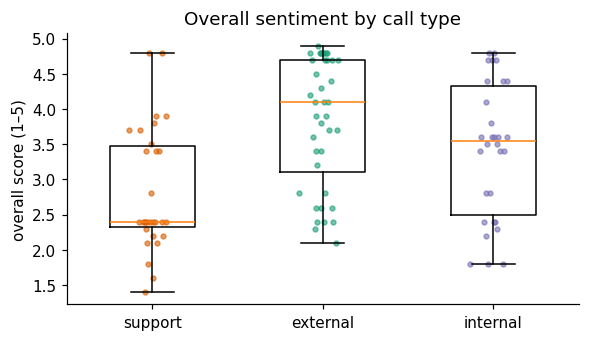

,count,mean,median,min,max
call_type,,,,,
support,30,2.83,2.40,1.4,4.8
external,40,3.85,4.10,2.1,4.9
internal,30,3.42,3.55,1.8,4.8


In [4]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.boxplot([cs[cs.call_type == t].sentiment_score for t in TYPE_ORDER], labels=TYPE_ORDER, widths=0.5)
for i, t in enumerate(TYPE_ORDER, 1):
    y = cs[cs.call_type == t].sentiment_score
    ax.scatter(np.random.default_rng(0).normal(i, 0.06, len(y)), y, s=10, alpha=.6, color=COLORS[t])
ax.set(ylabel="overall score (1–5)", title="Overall sentiment by call type"); plt.show()
cs.groupby("call_type").sentiment_score.agg(["count", "mean", "median", "min", "max"]).reindex(TYPE_ORDER).round(2)

> **Finding:** external (3.85) > internal (3.42) > support (2.83) — expected, since support calls start from a problem.
> The *spread* matters more than the means: every type spans almost the whole scale (support 1.4–4.8, external 2.1–4.9),
> so call type alone predicts little. Something else is driving sentiment — the next sections find it.

## 3. Whose sentiment? Customers vs Aegis staff

A call's overall score blends both sides. Staff are trained to stay positive, so blending hides how the *customer* feels.

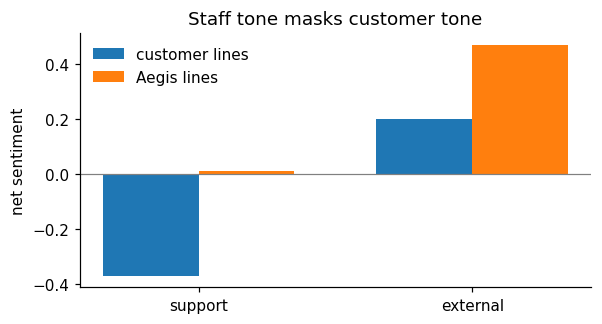

,net_customer,net_aegis,gap
call_type,,,
support,-0.37,0.01,0.38
external,0.20,0.47,0.27
internal,NaN,0.04,NaN


In [5]:
side = cs.groupby("call_type")[["net_customer", "net_aegis", "gap"]].mean().reindex(TYPE_ORDER).round(2)
fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(2)
for i, (col, lab) in enumerate([("net_customer", "customer lines"), ("net_aegis", "Aegis lines")]):
    ax.bar(x + i * 0.35, side.loc[["support", "external"], col], 0.35, label=lab)
ax.axhline(0, c="grey", lw=.8); ax.set_xticks(x + .175, ["support", "external"]); ax.set_ylabel("net sentiment")
ax.set_title("Staff tone masks customer tone"); ax.legend(frameon=False); plt.show()
side

In [6]:
# The gap is widest exactly when customers are unhappiest
cust = cs[cs.call_type != "internal"]
print(f"corr(customer net, politeness gap) = {np.corrcoef(cust.net_customer, cust.gap)[0, 1]:.2f}")
cust.nsmallest(5, "net_customer")[["title", "net_customer", "net_aegis", "gap", "sentiment_score"]].round(2)

corr(customer net, politeness gap) = -0.80


,title,net_customer,net_aegis,gap,sentiment_score
15,URGENT: Blackridge Investments - Complete Loss of Threat Visibility,-1.00,0.00,1.00,1.6
58,Support Case #3266 - Trailhead Marketplace Detect Alerts Not Firing,-1.00,-0.32,0.68,1.4
66,Support Case #6573 - Ridgeline Logistics Detect Data Gaps,-0.94,-0.04,0.90,2.1
95,URGENT: Cobalt Software - Aegis Detect Dashboard Down,-0.94,-0.16,0.79,1.8
62,ESCALATION: Northstar Pharma - Detect Outage Impact on Compliance,-0.87,-0.39,0.48,2.1


> **Finding:** on support calls customers are net **−0.37** while staff sit at **+0.01**; on external calls staff run
> +0.27 above customers. The gap grows as customers get angrier — staff hold a steady tone, which is good service but bad
> measurement: a whole-call score would under-report pain on exactly the calls that matter.
>
> **Decision:** every trend below uses **customer-side net sentiment** for customer calls. *Why it matters:* any CSAT proxy
> built from whole-call sentiment would systematically flatter the support team.

## 4. Trend over time

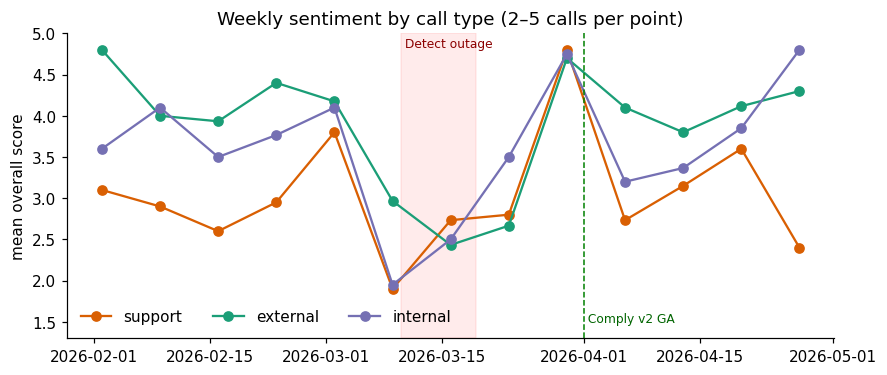

In [7]:
wk = cs.pivot_table(index="week", columns="call_type", values="sentiment_score", aggfunc="mean")[TYPE_ORDER]
n_wk = cs.pivot_table(index="week", columns="call_type", values="meeting_id", aggfunc="count")[TYPE_ORDER]
fig, ax = plt.subplots(figsize=(9, 3.6))
for t in TYPE_ORDER:
    ax.plot(wk.index, wk[t], marker="o", color=COLORS[t], label=t)
ax.axvspan(OUTAGE_START.tz_localize(None), OUTAGE_END.tz_localize(None), color="red", alpha=.08)
ax.text(OUTAGE_START.tz_localize(None), 4.95, " Detect outage", color="darkred", fontsize=8, va="top")
ax.axvline(COMPLY_V2_GA.tz_localize(None), color="green", ls="--", lw=1)
ax.text(COMPLY_V2_GA.tz_localize(None), 1.5, " Comply v2 GA", color="darkgreen", fontsize=8)
ax.set(ylabel="mean overall score", ylim=(1.3, 5), title="Weekly sentiment by call type (2–5 calls per point)")
ax.legend(frameon=False, ncol=3); plt.show()

In [8]:
tbl = cs.pivot_table(index="call_type", columns="period", values="sentiment_score", aggfunc="mean", observed=False).reindex(TYPE_ORDER)
tbl_c = cs.pivot_table(index="call_type", columns="period", values="net_customer", aggfunc="mean", observed=False).reindex(["support", "external"])
n = cs.pivot_table(index="call_type", columns="period", values="meeting_id", aggfunc="count", observed=False).reindex(TYPE_ORDER)
display(tbl.round(2).astype(str) + "  (n=" + n.astype(str) + ")")
print("Customer-side net sentiment:"); tbl_c.round(2)

period,pre-outage,outage,post-outage
call_type,,,
support,3.07 (n=10),2.15 (n=8),3.08 (n=12)
external,4.25 (n=15),2.27 (n=3),3.8 (n=22)
internal,3.8 (n=9),2.17 (n=6),3.7 (n=15)


Customer-side net sentiment:


period,pre-outage,outage,post-outage
call_type,,,
support,-0.27,-0.74,-0.20
external,0.35,-0.72,0.23


> **Findings:**
> - **The outage hits every call type in the same week** — all three fall to ≈ 2.2 (10–18 Mar). It was a company-wide
>   event, not a support event: internal calls drop as far as customer calls.
> - **Comply v2 GA week (30 Mar) is the high point of the quarter** for all three types (≈ 4.8).
> - **On the surface, everything recovers:** external 4.25 → 2.27 → 3.80, internal 3.80 → 2.17 → 3.70.
>   Support barely moves outside the outage (3.07 → 3.08) — it's structurally lower, not outage-driven.
> - But customers on external calls are still below where they started (net **+0.35 → +0.23**). §5 explains why.

## 5. Did it really recover? Separating the outage from the launch

After the outage two very different things are happening: outage fallout and the Comply v2 launch.
Using the topic labels from notebook 02, split post-outage calls by what they're about.

In [9]:
outage_calls = set(themes[themes.theme.str.startswith("Outage")].meeting_id)
comply_calls = set(themes[themes.theme.str.startswith("Compliance")].meeting_id)
post = cs[cs.period == "post-outage"].copy()
post["topic"] = np.select([post.meeting_id.isin(outage_calls), post.meeting_id.isin(comply_calls)],
                          ["outage-related", "compliance / Comply v2"], "other")
print(f"Post-outage overall: {post.sentiment_score.mean():.2f}")
post.groupby("topic").agg(calls=("meeting_id", "size"), score=("sentiment_score", "mean"),
                          customer_net=("net_customer", "mean")).round(2)

Post-outage overall: 3.59


,calls,score,customer_net
topic,,,
compliance / Comply v2,15,4.39,0.54
other,11,3.37,-0.23
outage-related,23,3.17,-0.15


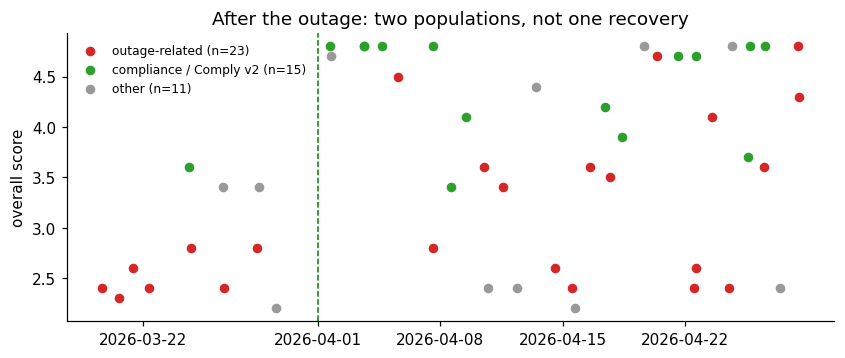

,start,title,call_type,sentiment_score
24,2026-04-05,Aegis / Trailhead Marketplace - Renewal Confirmation,external,4.5
54,2026-04-07,Detect Reliability - 30-Day Review,internal,2.8
71,2026-04-10,Competitive Response Strategy,internal,3.6
4,2026-04-11,Aegis / Cobalt Software - Q2 Planning,external,3.4
53,2026-04-14,Aegis / Ironworks Corp - Vendor Comparison Discussion,external,2.6
84,2026-04-15,Support Case #6147 - Summit Trust Detect Alert Delays,support,2.4
64,2026-04-16,Aegis / Pinnacle Insurance - Detect Roadmap Review,external,3.6
28,2026-04-17,Weekly Engineering Standup,internal,3.5
98,2026-04-20,SOC 2 Type II - Final Review,internal,4.7
32,2026-04-22,Aegis / Brightpath Commerce - Competitive Evaluation,external,2.6


In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for topic, col in [("outage-related", "#d62728"), ("compliance / Comply v2", "#2ca02c"), ("other", "#999999")]:
    d = post[post.topic == topic]
    ax.scatter(d.start.dt.tz_localize(None), d.sentiment_score, color=col, label=f"{topic} (n={len(d)})", s=28)
ax.axvline(COMPLY_V2_GA.tz_localize(None), color="green", ls="--", lw=1)
ax.set(ylabel="overall score", title="After the outage: two populations, not one recovery"); ax.legend(frameon=False, fontsize=8)
plt.show()
post[(post.topic == "outage-related") & (post.start >= COMPLY_V2_GA)][["start", "title", "call_type", "sentiment_score"]] \
    .assign(start=lambda d: d.start.dt.date).sort_values("start")

> **Finding — the headline of this notebook:** the post-outage "recovery" is a **mix effect**. Calls that still discuss the
> outage average **3.17** (customer net −0.15), against **4.39** for Comply v2 calls (customer net +0.54) — and outage calls
> keep appearing to the end of April (Brightpath's competitive evaluation 22 Apr, Win/Loss analysis 24 Apr). The overall
> post-outage average (3.59) is that blend. (§8: the *gap* between the two groups holds with an independent labeller; whether
> outage calls are net negative or just low-positive depends on the labeller, so I don't claim the sign.)
>
> **Why someone should care:** a dashboard showing average sentiment would tell leadership the outage is behind us by April.
> It isn't — it's still in renewal and competitive conversations six weeks later, just diluted by a successful launch.
> **Recommendation:** track sentiment *per topic*, not in aggregate, and keep an "outage-related" view open until those
> calls stop appearing.

## 6. Do calls end better than they start?

Customer net sentiment in the first, middle and last third of each call.

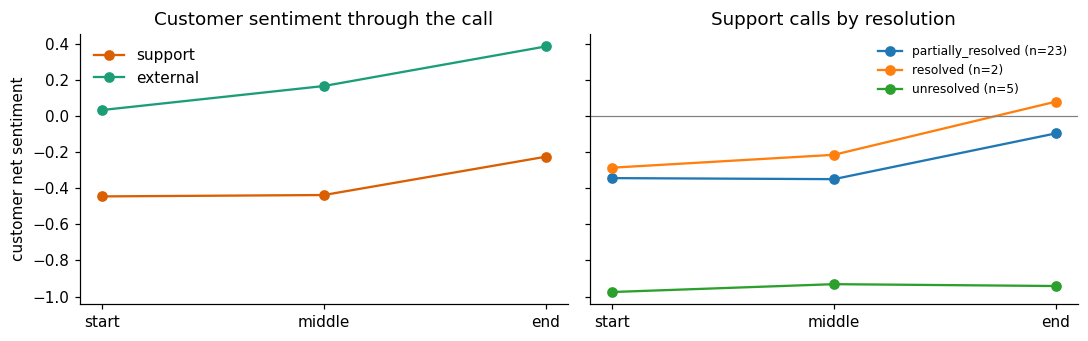

,start,middle,end
call_type,,,
external,0.03,0.17,0.39
support,-0.44,-0.44,-0.22


In [11]:
arcs = call_arcs(sentences).merge(cs[["meeting_id", "call_type", "resolution", "period", "llm_incident"]])
cust_arc = arcs[arcs.side == "customer"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for t in ["support", "external"]:
    axes[0].plot(["start", "middle", "end"], cust_arc[cust_arc.call_type == t][["start", "middle", "end"]].mean(),
                 marker="o", color=COLORS[t], label=t)
axes[0].set(title="Customer sentiment through the call", ylabel="customer net sentiment"); axes[0].legend(frameon=False)
sup = cust_arc[cust_arc.call_type == "support"]
for res, g in sup.groupby("resolution"):
    axes[1].plot(["start", "middle", "end"], g[["start", "middle", "end"]].mean(), marker="o", label=f"{res} (n={len(g)})")
axes[1].axhline(0, c="grey", lw=.8); axes[1].set(title="Support calls by resolution"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
cust_arc.groupby("call_type")[["start", "middle", "end"]].mean().round(2)

In [12]:
print("Support-call resolution (from notebook 02 extraction):", sup.resolution.value_counts().to_dict())
cs[(cs.call_type == "support") & (cs.resolution == "unresolved")][["start", "title", "net_customer", "llm_incident"]] \
    .assign(start=lambda d: d.start.dt.date)

Support-call resolution (from notebook 02 extraction): {'partially_resolved': 23, 'unresolved': 5, 'resolved': 2}


,start,title,net_customer,llm_incident
15,2026-03-12,URGENT: Blackridge Investments - Complete Loss of Threat Visibility,-1.000000,True
58,2026-03-11,Support Case #3266 - Trailhead Marketplace Detect Alerts Not Firing,-1.000000,True
62,2026-03-15,ESCALATION: Northstar Pharma - Detect Outage Impact on Compliance,-0.869565,True
66,2026-03-13,Support Case #6573 - Ridgeline Logistics Detect Data Gaps,-0.944444,True
95,2026-03-10,URGENT: Cobalt Software - Aegis Detect Dashboard Down,-0.944444,True


> **Findings:**
> - **External calls end much better than they start** (customer +0.03 → +0.39). Account managers reliably turn the
>   conversation around — a strength worth knowing about when deciding who handles escalations.
> - **Support calls improve, but stay negative** (−0.44 → −0.22): customers leave less angry, not happy.
> - **Only 2 of 30 support calls end fully resolved**; 23 end "partially resolved" (workaround / escalation).
>   The **5 unresolved calls never recover** (−0.98 → −0.94) — all five are outage calls from 10–15 March,
>   where support had no fix to give because the fault was platform-side.
>
> **Why it matters:** "partially resolved" is the norm, so first-contact resolution is low; and during a platform incident
> support is structurally unable to resolve anything — those customers need a different channel (status updates, an incident
> lead), not a ticket. The customer's mood at the *end* of a support call is a cheap, real-time signal for which cases need a
> follow-up from someone senior.

## 7. Which topics carry the pain?

Customer net sentiment per theme (customer calls only, threshold ≥ 0.6 from notebook 02).

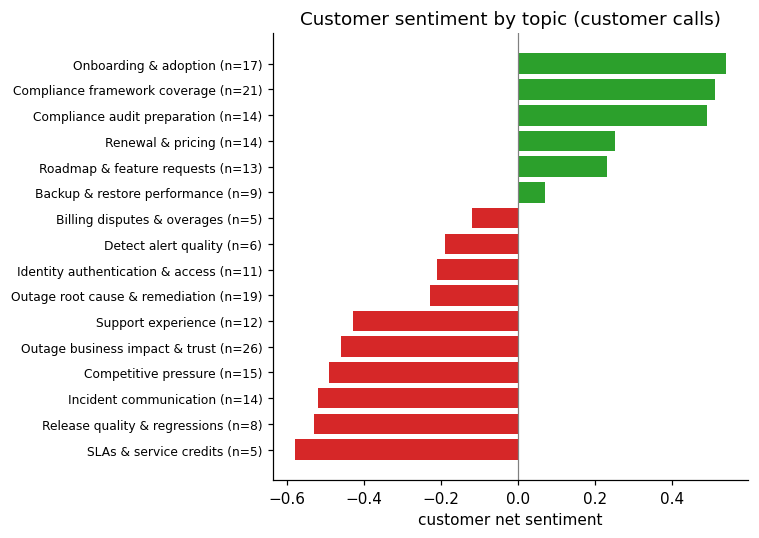

calls  score  customer_net   gap
l1                      theme                                                             
Reliability & Incidents SLAs & service credits                5   2.30         -0.58  0.68
Engineering & Delivery  Release quality & regressions         8   2.49         -0.53  0.52
Reliability & Incidents Incident communication               14   2.45         -0.52  0.54
Commercial              Competitive pressure                 15   2.51         -0.49  0.60
Reliability & Incidents Outage business impact & trust       26   2.57         -0.46  0.54
Customer Experience     Support experience                   12   2.68         -0.43  0.44
Reliability & Incidents Outage root cause & remediation      19   2.97         -0.23  0.44
Product Gaps            Identity authentication & access     11   3.12         -0.21  0.36
                        Detect alert quality                  6   3.13         -0.19  0.27
Commercial              Billing disputes & overages           5   3.50         -0.12  0.12
Product Gaps            Backup & restore performance          9   3.78          0.07  0.22
Customer Experience     Roadmap & feature requests           13   3.97          0.23  0.14
Commercial              Renewal & pricing                    14   3.74          0.25  0.22
Product Gaps            Compliance audit preparation         14   4.37          0.49  0.19
                        Compliance framework coverage        21   4.30          0.51  0.14
Customer Experience     Onboarding & adoption                17   4.62          0.54  0.15

In [13]:
tm = themes.merge(cs[["meeting_id", "sentiment_score", "net_customer", "gap"]], on="meeting_id")
by_theme = (tm[tm.call_type != "internal"].groupby(["l1", "theme"])
              .agg(calls=("meeting_id", "nunique"), score=("sentiment_score", "mean"),
                   customer_net=("net_customer", "mean"), gap=("gap", "mean"))
              .query("calls >= 4").sort_values("customer_net").round(2))
fig, ax = plt.subplots(figsize=(7, 5))
y = np.arange(len(by_theme))
ax.barh(y, by_theme.customer_net, color=np.where(by_theme.customer_net < 0, "#d62728", "#2ca02c"))
ax.set_yticks(y, [f"{t} (n={n})" for (_, t), n in zip(by_theme.index, by_theme.calls)], fontsize=8)
ax.axvline(0, c="grey", lw=.8); ax.set(xlabel="customer net sentiment", title="Customer sentiment by topic (customer calls)")
plt.tight_layout(); plt.show()
by_theme

> **Findings:**
> - **The most negative topics are about *how incidents were handled*, not the incident itself:** *SLAs & service credits*
>   (−0.58), *Incident communication* (−0.52) and *Support experience* (−0.43) sit well below *Outage root cause* (−0.23).
>   Customers forgive the failure more than the silence — "we were never notified" recurs in these calls.
> - ***Release quality & regressions* is the second most negative topic (−0.53):** these are mostly April support cases caused
>   by the outage *remediation* (circuit-breaker timeouts, sync delays) — the fix generated its own wave of pain.
> - ***Competitive pressure* is among the most negative topics** and has one of the largest staff-vs-customer gaps:
>   staff stay upbeat on exactly the calls where customers are evaluating alternatives.
> - **Positive topics are forward-looking:** onboarding, audit preparation, framework coverage (Comply v2), roadmap.
> - Caveat: several topics have only 5–8 customer calls; read the ranking, not the decimals.
>
> **Recommendation:** for engineering, the outage fix is necessary but not sufficient — a proactive incident-communication
> process and clearer SLA terms address the topics with the worst customer sentiment, at far lower cost than new features.

## 8. Robustness — do the conclusions survive a different labeller?

The same headline numbers recomputed with the local model's line labels.

In [14]:
# Each finding is a *comparison*, so test the comparison (a difference), not the raw level.
def headline(c, a):
    sup, ext, post_ = c[c.call_type == "support"], c[c.call_type == "external"], c[c.period == "post-outage"]
    ext_p = ext.groupby("period", observed=False).net_customer.mean()
    return {
        "§3 support: customer − Aegis": sup.net_customer.mean() - sup.net_aegis.mean(),
        "§4 external customer: outage − pre-outage": ext_p["outage"] - ext_p["pre-outage"],
        "§4 external customer: post − pre-outage": ext_p["post-outage"] - ext_p["pre-outage"],
        "§5 post-outage: outage-related − Comply calls": post_[post_.meeting_id.isin(outage_calls)].net_customer.mean()
                                                       - post_[post_.meeting_id.isin(comply_calls - outage_calls)].net_customer.mean(),
        "§6 external customer arc: end − start": a[(a.side == "customer") & (a.call_type == "external")].pipe(lambda d: d.end.mean() - d.start.mean()),
        "§6 support customer arc: end − start": a[(a.side == "customer") & (a.call_type == "support")].pipe(lambda d: d.end.mean() - d.start.mean()),
    }
a_local = call_arcs(loc.assign(sentiment=loc.local)).merge(cs[["meeting_id", "call_type"]])
cs_local = cs_local.merge(ct)
rob = pd.DataFrame({"provided labels": headline(cs, arcs), "local model": headline(cs_local, a_local)}).round(2)
rob["same direction"] = np.sign(rob.iloc[:, 0]) == np.sign(rob.iloc[:, 1])
rob

,provided labels,local model,same direction
§3 support: customer − Aegis,-0.38,-0.18,True
§4 external customer: outage − pre-outage,-1.07,-0.52,True
§4 external customer: post − pre-outage,-0.12,-0.07,True
§5 post-outage: outage-related − Comply calls,-0.69,-0.31,True
§6 external customer arc: end − start,0.35,0.38,True
§6 support customer arc: end − start,0.22,0.38,True


> **Finding:** every comparison keeps its direction under the independent model, so **the conclusions don't depend on the
> labeller**. Magnitudes do: the local model misses business-context negativity (§1), so most gaps roughly halve, and the
> *level* of some groups changes sign (e.g. post-outage outage-related calls: −0.15 provided vs +0.10 local).
> **Decision:** the deck states directions and relative gaps, and quotes absolute levels only with the labeller named.

## Summary — what the trends mean

| Finding | What it could indicate | Who should care / recommendation |
|---|---|---|
| Line labels vs independent model: κ 0.45 per line, r 0.95 per call; all comparisons hold | Labels are noisy per line, reliable in aggregate | Analysts: act on comparisons across calls, never on a single line |
| Support customers −0.37 while staff +0.01; gap widest on angriest calls | Whole-call sentiment flatters support | Support leaders: measure customer-side sentiment only |
| All three call types fall to ≈ 2.2 in outage week | The outage was a company-wide event | Eng leadership: incidents need a cross-functional response, not just SRE |
| Post-outage "recovery" is a mix effect: outage calls 3.17 vs Comply calls 4.39, into late April | Averages hide lingering damage behind a successful launch | Sales/CS: keep outage-affected accounts on a watch list; track sentiment per topic |
| External calls end +0.36 better than they start | AMs repair relationships in-call | CS: route at-risk escalations to AMs, not only support |
| 2/30 support calls fully resolved; the 5 unresolved (all outage week) never recover | Low first-contact resolution; support can't fix platform incidents | Support: end-of-call customer sentiment triggers senior follow-up; incident lead owns outage callers |
| Worst topics: SLAs, incident communication, regressions from the fix — not the root cause | Customers punish silence and side effects more than the failure | Eng: proactive incident comms, clear SLAs, and regression testing of remediation |
| Competitive pressure: very negative, large staff/customer gap | Churn risk hides behind upbeat calls | Sales: flag competitor mentions for leadership review |

Account-level journeys (e.g. Stratos Cloud 4.7 → 2.4, Summit Trust 3.8 → 2.4) are developed in notebook 04.

In [15]:
cs.drop(columns=["emails", "topics", "action_items", "summary", "products"]).to_csv(REPORTS / "call_sentiment.csv", index=False)
print("Wrote reports/call_sentiment.csv")

Wrote reports/call_sentiment.csv
